In [1]:
##########################
# RDE NUMERICAL SOLUTION #
##########################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np 

In [2]:
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
b2 = kappa2*theta2
epsilon2 = -kappa2

def funVasicek(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2, epsilon1*beta1-1, epsilon2*beta2-1]
def funCIR(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2, epsilon1*beta1+(1/2)*sigma1**2*beta1**2-1, epsilon2*beta2+(1/2)*sigma2**2*beta2**2-1]

U_0 = [0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultVasicek = solve_ivp(funVasicek, (0, 10), U_0, t_eval=t_pts, method='RK45')

U_0 = [0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultCIR = solve_ivp(funCIR, (0, 10), U_0, t_eval=t_pts, method='RK45')

resultVasicek, resultCIR

(  message: 'The solver successfully reached the end of the integration interval.'
      nfev: 62
      njev: 0
       nlu: 0
       sol: None
    status: 0
   success: True
         t: array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])
  t_events: None
         y: array([[ 0.        , -0.15756962, -0.52434511, -1.0035023 , -1.54479142,
         -2.12158378, -2.71809852, -3.32649961, -3.94153923, -4.56037643,
         -5.18163147],
        [ 0.        , -0.752042  , -1.16469653, -1.39116122, -1.51567464,
         -1.58347721, -1.62125786, -1.64156334, -1.65275758, -1.65908957,
         -1.66236531],
        [ 0.        , -0.78696794, -1.26425539, -1.55374235, -1.72946291,
         -1.83572248, -1.90054142, -1.93954786, -1.96325109, -1.97775944,
         -1.98638789]])
  y_events: None,
   message: 'The solver successfully reached the end of the integration interval.'
      nfev: 68
      njev: 0
       nlu: 0
       sol: None
    status: 0
   success: True
         t: array

In [3]:
###########################
# SWAPTION EXERCISE BOUND #
###########################

# Consider swaption given by t=0, S=5, T=10 and yearly cashflows in between

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [4]:
#ATMF strike Vasicek + sanity check

VasPtT1 = np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*0.05+resultVasicek.y[2,1]*0.05)
VasPtT2 = np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*0.05+resultVasicek.y[2,2]*0.05)
VasPtT3 = np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*0.05+resultVasicek.y[2,3]*0.05)
VasPtT4 = np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*0.05+resultVasicek.y[2,4]*0.05)
VasPtS = np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*0.05+resultVasicek.y[2,5]*0.05)
VasPtT = np.exp(resultVasicek.y[0,6]+resultVasicek.y[1,6]*0.05+resultVasicek.y[2,6]*0.05)

VasATMFSwapK = (VasPtS - VasPtT)/(VasPtT)
KVasicek = VasATMFSwapK+(VasATMFSwapK*0)
KVasicek, VasPtS-(1+KVasicek)*VasPtT

(0.8251181444754155, 0.0)

In [422]:
#ATMF strike CIR + sanity check

CIRPtT1 = np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*0.05+resultCIR.y[2,1]*0.05)
CIRPtT2 = np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*0.05+resultCIR.y[2,2]*0.05)
CIRPtT3 = np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*0.05+resultCIR.y[2,3]*0.05)
CIRPtT4 = np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*0.05+resultCIR.y[2,4]*0.05)
CIRPtS = np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*0.05+resultCIR.y[2,5]*0.05)
CIRPtT = np.exp(resultCIR.y[0,6]+resultCIR.y[1,6]*0.05+resultCIR.y[2,6]*0.05)

CIRATMFSwapK = (CIRPtS - CIRPtT)/(CIRPtT)
KCIR = CIRATMFSwapK+(CIRATMFSwapK*0.2)
KCIR, CIRPtS-(1+KCIR)*CIRPtT

(1.0998201378465122, -0.008303415353714885)

In [6]:
###################################
# SIMULATION a.k.a. "TRUE PRICES" #
###################################

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from scipy.stats import ncx2
from IPython.display import display

In [7]:
def VasicekProcess(kappa1, kappa2, theta1, theta2, sigma1, sigma2, r0, T, dt, rho):
    N = int(T / dt)
    W_1 = [r0]
    W_2 = [r0]
    
    for i in range(N):
        Z1 = np.random.normal(scale = 1)
        Z2 = np.random.normal(scale = 1)
        Z3 = rho * Z1 + np.sqrt(1 - rho**2) * Z2
        r_new1 = np.exp(-kappa1 * dt) * W_1[i] + theta1 * (1 - np.exp(-kappa1 * dt)) + sigma1 * np.sqrt((1 - np.exp(-2 * kappa1 * dt))/(2 * kappa1)) * Z1
        r_new2 = np.exp(-kappa2 * dt) * W_2[i] + theta2 * (1 - np.exp(-kappa2 * dt)) + sigma2 * np.sqrt((1 - np.exp(-2 * kappa2 * dt))/(2 * kappa2)) * Z3
        W_1.append(r_new1)
        W_2.append(r_new2)
        
    return [W_1, W_2]

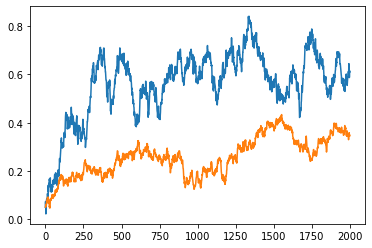

In [8]:
VasicekList = VasicekProcess(0.6,0.5,0.4,0.3,0.2,0.1,0.05,10,0.005,0)
plt.plot(VasicekList[0])
plt.plot(VasicekList[1])
plt.show()

In [24]:
#Storage of sample paths
#Careful...slow to execute for N>=10k

NsimsVasicek = 100000
listVasicekPaths = []
for i in range(NsimsVasicek):
    VasicekPath = VasicekProcess(0.6,0.5,0.4,0.3,0.2,0.1,0.05,10,0.005,0)
    listVasicekPaths.append(VasicekPath)

In [ ]:
#Monte Carlo simulated prices
listVasicekSwaption = []
listMaximizer = []
for i in range(NsimsVasicek-1):
    VasicekZCB10 = np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*listVasicekPaths[i][0][1000]+resultVasicek.y[2,1]*listVasicekPaths[i][1][1000])
    Maximizer = max(1-(1+KVasicek)*VasicekZCB10,0)
    listMaximizer.append(Maximizer)
for i in range(NsimsVasicek-1):
    VasicekSwaption = listMaximizer[i]*np.exp(-np.trapz(listVasicekPaths[i][0][0:1000])/200-np.trapz(listVasicekPaths[i][1][0:1000])/200).tolist()
    listVasicekSwaption.append(VasicekSwaption)
VasicekSwaptionPriceSim = np.mean(listVasicekSwaption)
VasicekSwaptionPriceSim

In [601]:
#Simulated prob. under fwd. measure

listProbVasicekSwaption = []
indicVas = [1 if x>0 else 0 for x in listMaximizer]
for i in range(NsimsVasicek-1):
    ProbVasicekSwaption = indicVas[i]*np.exp(-np.trapz(listVasicekPaths[i][0][0:1000])/200-np.trapz(listVasicekPaths[i][1][0:1000])/200).tolist()
    listProbVasicekSwaption.append(ProbVasicekSwaption)
VasicekSwaptionProbSim = np.mean(listProbVasicekSwaption)
VasicekSwaptionProbSim/VasPtS

0.5312254347830802

In [33]:
def cir_simulation(kappa1, theta1, sigma1, kappa2, theta2, sigma2, n, t_start, t_end, r01, r02):
    
    dt = (t_end - t_start) / n
    W_1 = [r01]
    W_2 = [r02]

    mu1 = 4 * theta1 * kappa1 / sigma1**2
    mu2 = 4 * theta2 * kappa2 / sigma2**2
    for i in range(n):
        non_central1 = 4 * kappa1 * np.exp(-kappa1 * dt) / (sigma1**2 * (1 - np.exp(-kappa1 * dt))) * W_1[i]
        non_central2 = 4 * kappa2 * np.exp(-kappa2 * dt) / (sigma2**2 * (1 - np.exp(-kappa2 * dt))) * W_2[i]
        r_new1 = ncx2.rvs(mu1, non_central1) * sigma1**2 * (1-np.exp(-kappa1 * dt)) / (4 * kappa1)
        r_new2 = ncx2.rvs(mu2, non_central2) * sigma2**2 * (1-np.exp(-kappa2 * dt)) / (4 * kappa2)
        W_1.append(r_new1)
        W_2.append(r_new2)
    return [W_1, W_2]

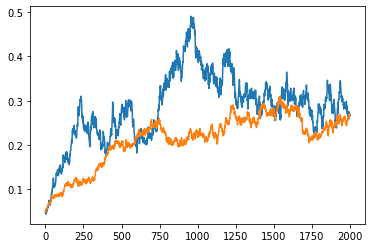

In [34]:
CIRList = cir_simulation(0.6,0.4,0.2,0.5,0.3,0.1,2000,0,10,0.05,0.05)
plt.plot(CIRList[0])
plt.plot(CIRList[1])
plt.show()

In [35]:
#Careful.....slow to execute for N>=1k
NsimsCIR = 20000
listCIRPaths = []
for i in range(NsimsCIR):
    CIRPath = cir_simulation(0.6,0.4,0.2,0.5,0.3,0.1,2000,0,10,0.05,0.05)
    listCIRPaths.append(CIRPath)

In [423]:
listMaximizerCIR = []
listCIRSwaption = []
for i in range(NsimsCIR-1):
    CIRZCB10 = np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*listCIRPaths[i][0][1000]+resultCIR.y[2,1]*listCIRPaths[i][1][1000])
    MaximizerCIR = max(1-(1+KCIR)*CIRZCB10,0)
    listMaximizerCIR.append(MaximizerCIR)
for i in range(NsimsCIR-1):
    CIRSwaption = listMaximizerCIR[i]*np.exp(-np.trapz(listCIRPaths[i][0][0:1000])/200-np.trapz(listCIRPaths[i][1][0:1000])/200).tolist()
    listCIRSwaption.append(CIRSwaption)
CIRSwaptionPriceSim = np.mean(listCIRSwaption)
CIRSwaptionPriceSim

0.0007629764906449927

In [367]:
listProbCIRSwaption = []
indicCIR = [1 if x>0 else 0 for x in listMaximizerCIR]
for i in range(NsimsCIR-1):
    ProbCIRSwaption = indicCIR[i]*np.exp(-np.trapz(listCIRPaths[i][0][0:1000])/200-np.trapz(listCIRPaths[i][1][0:1000])/200).tolist()
    listProbCIRSwaption.append(ProbCIRSwaption)
CIRSwaptionProbSim = np.mean(listProbCIRSwaption)
CIRSwaptionProbSim/CIRPtS

0.49307470909806217

In [11]:
#################################################
# FETCH QUANTILES FROM RESPECTIVE DISTRIBUTIONS #
#################################################

from scipy.stats import norm
import numpy as np

In [12]:
#Vasicek 1st factor distr.

r0 = 0.05
expiryT = 5
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
EV1 = r0*np.exp(-kappa1*expiryT)+theta1*(1-np.exp(-kappa1*expiryT))
Var1 = (sigma1**2/kappa1)*(1-np.exp(-2*kappa1*expiryT))
lowerquantile1 = norm.ppf((1-0.9545)/2, loc=EV1, scale=Var1)
upperquantile1 = norm.ppf((1+0.9545)/2, loc=EV1, scale=Var1)

Var1, (lowerquantile1, EV1, upperquantile1)

(0.06650141652155558,
 (0.249571530505351, 0.38257452607124764, 0.5155775216371442))

In [13]:
#Vasicek 2nd factor distr.

r0 = 0.05
expiryT = 5
kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
EV2 = r0*np.exp(-kappa2*expiryT)+theta2*(1-np.exp(-kappa2*expiryT))
Var2 = (sigma2**2/kappa2)*(1-np.exp(-2*kappa2*expiryT))
lowerquantile2 = norm.ppf((1-0.9545)/2, loc=EV2, scale=Var2)
upperquantile2 = norm.ppf((1+0.9545)/2, loc=EV2, scale=Var2)

Var2, (lowerquantile2, EV2, upperquantile2)

(0.019865241060018295,
 (0.23974821967533397, 0.2794787503440253, 0.3192092810127166))

In [280]:
#CIR 1st factor distr.

r01 = 0.05
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
expiryT = 5
dt = expiryT - 0

mu1 = 4 * theta1 * kappa1 / sigma1**2
ncx2_init1 = r01
non_central1 = 4 * kappa1 * np.exp(-kappa1 * dt) / (sigma1**2 * (1 - np.exp(-kappa1 * dt))) * ncx2_init1
scale1 = sigma1**2 * (1-np.exp(-kappa1 * dt)) / (4 * kappa1)
X_1_new = ncx2(df=mu1,nc=non_central1,scale=scale1)
EV1newCIR = (mu1+non_central1)*scale1

X_1_new.ppf(0.5), X_1_new.var(), (X_1_new.ppf((1-0.9545)/2), EV1newCIR, X_1_new.ppf((1+0.9545)/2)), (X_1_new.ppf(1-0.9545), EV1newCIR, X_1_new.ppf(0.9545))

(0.3720023453599923,
 0.012196422593183173,
 (0.19487952478665166, 0.38257452607124764, 0.6336219896108802),
 (0.21732813018747554, 0.38257452607124764, 0.5870850867261865))

In [281]:
#CIR 2nd factor distr.

r02 = 0.05
kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
expiryT = 5
dt = expiryT - 0

mu2 = 4 * theta2 * kappa2 / sigma2**2
ncx2_init2 = r02
non_central2 = 4 * kappa2 * np.exp(-kappa2 * dt) / (sigma2**2 * (1 - np.exp(-kappa2 * dt))) * ncx2_init2
scale2 = sigma2**2 * (1-np.exp(-kappa2 * dt)) / (4 * kappa2)
X_2_new = ncx2(df=mu2,nc=non_central2,scale=scale2)
EV2newCIR = (mu2+non_central2)*scale2

X_2_new.ppf(0.5), X_2_new.var(), (X_2_new.ppf((1-0.9545)/2), EV2newCIR, X_2_new.ppf((1+0.9545)/2)), (X_2_new.ppf(1-0.9545), EV2newCIR, X_2_new.ppf(0.9545))

(0.2763809054033594,
 0.002603050900878677,
 (0.1870085832617806, 0.27947875034402525, 0.39052671495758956),
 (0.19932889034906184, 0.27947875034402525, 0.37113242114207795))

In [16]:
################################
# PLUG Y_S INTO EXERCISE BOUND #
################################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [18]:
# Solve P(x)-1=0 <=> P(x)=1

VasEnd1ExerciseBound = lambda Y1S1 : (1+KVasicek)*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S1+resultVasicek.y[2,1]*lowerquantile2)-1
VasY1S1_init_guess = 0.2
VasSolY1S1 = fsolve(VasEnd1ExerciseBound, VasY1S1_init_guess)

VasEnd2ExerciseBound = lambda Y1S2 : (1+KVasicek)*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S2+resultVasicek.y[2,1]*upperquantile2)-1
VasY1S2_init_guess = 0.2
VasSolY1S2 = fsolve(VasEnd2ExerciseBound, VasY1S2_init_guess)

x = [VasSolY1S1[0],VasSolY1S2[0]]
y = [lowerquantile2, upperquantile2]

#slope coef[0], intercept coef[1]

coefVas = np.polyfit(y,x,1)

(VasSolY1S1[0],VasSolY1S2[0]), (lowerquantile2, upperquantile2), coefVas, KVasicek

((0.33960993884318424, 0.25645858820879325),
 (0.23974821967533397, 0.3192092810127166),
 array([-1.04644148,  0.59049242]),
 0.8251181444754155)

In [427]:
# Solve P(x)-1=0 <=> P(x)=1

CIREnd1ExerciseBound = lambda Y1S1 : 1-(1+KCIR)*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S1+resultCIR.y[2,1]*X_2_new.ppf((1-0.9545)/2))
CIRY1S1_init_guess = 0.2
CIRSolY1S1 = fsolve(CIREnd1ExerciseBound, CIRY1S1_init_guess)

CIREnd2ExerciseBound = lambda Y1S2 : 1-(1+KCIR)*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S2+resultCIR.y[2,1]*X_2_new.ppf((1+0.9545)/2))
CIRY1S2_init_guess = 0.2
CIRSolY1S2 = fsolve(CIREnd2ExerciseBound, CIRY1S2_init_guess)

CIRx = [CIRSolY1S1[0],CIRSolY1S2[0]]
CIRy = [X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2)]

#slope coef[0], intercept coef[1]

coefCIR = np.polyfit(CIRy,CIRx,1)

(CIRSolY1S1[0], CIRSolY1S2[0]), (X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2)), X_2_new.ppf(0.5), coefCIR, KCIR

((0.577376723349752, 0.3636318431609959),
 (0.1870085832617806, 0.39052671495758956),
 0.2763809054033594,
 array([-1.05024982,  0.77378245]),
 1.0998201378465122)

In [22]:
###############################################
# CHARACTERISTIC FUNCTIONS UNDER FWD. MEASURE #
###############################################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
from scipy.integrate import quad
import numpy as np

In [132]:
#test code

kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
b2 = kappa2*theta2
epsilon2 = -kappa2

t=0
S=5
T=10
r0=0.05
    
def funVasicek_general(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2, epsilon1*beta1-1, epsilon2*beta2-1]
def funCIR_general(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2, epsilon1*beta1+(1/2)*sigma1**2*beta1**2-1, epsilon2*beta2+(1/2)*sigma2**2*beta2**2-1]

def VasicekCharFuncCoeffs(init):
    t_pts = np.linspace(0, 10, 11)
    resultVasicekFwd = solve_ivp(funVasicek_general, (0, 10), init, t_eval=t_pts, method='RK45')
    return resultVasicekFwd
def CIRCharFuncCoeffs(init):
    t_pts = np.linspace(0, 10, 11)
    resultVasicekFwd = solve_ivp(funCIR_general, (0, 10), init, t_eval=t_pts, method='RK45')
    return resultVasicekFwd

VasicekATS = VasicekCharFuncCoeffs([0,0,0]).y[0,T-S]
VasicekB1TS = VasicekCharFuncCoeffs([0,0,0]).y[1,T-S]
VasicekB2TS = VasicekCharFuncCoeffs([0,0,0]).y[2,T-S]
VasicekATt = VasicekCharFuncCoeffs([0,0,0]).y[0,T-t]
VasicekB1Tt = VasicekCharFuncCoeffs([0,0,0]).y[1,T-t]
VasicekB2Tt = VasicekCharFuncCoeffs([0,0,0]).y[2,T-t]
CIRATS = CIRCharFuncCoeffs([0,0,0]).y[0,T-S]
CIRB1TS = CIRCharFuncCoeffs([0,0,0]).y[1,T-S]
CIRB2TS = CIRCharFuncCoeffs([0,0,0]).y[2,T-S]
CIRATt = CIRCharFuncCoeffs([0,0,0]).y[0,T-t]
CIRB1Tt = CIRCharFuncCoeffs([0,0,0]).y[1,T-t]
CIRB2Tt = CIRCharFuncCoeffs([0,0,0]).y[2,T-t]

def VasicekFwdCharFunc(z):
    b = [1,-coefVas[0]]
    ExponentTerm1 = VasicekATS
    ExponentTerm2 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[0,S-t]
    ExponentTerm3 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[1,S-t]
    ExponentTerm4 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[2,S-t]
    PtT = np.exp(VasicekATt + VasicekB1Tt*r0 + VasicekB2Tt*r0)
    return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0)/PtT
def CIRFwdCharFunc(z):
    b = [1,-coefCIR[0]]
    ExponentTerm1 = CIRATS
    ExponentTerm2 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[0,S-t]
    ExponentTerm3 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[1,S-t]
    ExponentTerm4 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[2,S-t]
    PtT = np.exp(CIRATt + CIRB1Tt*r0 + CIRB2Tt*r0)
    return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0)/PtT

def VasicekImagProbFunc(z):
    a = coefVas[1]
    return np.imag(np.exp(-1j*z*a)*VasicekFwdCharFunc(z))/z
def CIRImagProbFunc(z):
    a = coefCIR[1]
    return np.imag(np.exp(-1j*z*a)*CIRFwdCharFunc(z))/z

CDFVasicekFwd = 1/2 - (1/np.pi) * quad(VasicekImagProbFunc, 0, np.inf)[0]
ProbVasicekFwd = 1 - CDFVasicekFwd

CDFCIRFwd = 1/2 - (1/np.pi) * quad(CIRImagProbFunc, 0, np.inf)[0]
ProbCIRFwd = 1 - CDFCIRFwd

(ProbVasicekFwd, ProbCIRFwd)

(0.396355368213133, 0.28382024423365204)

In [372]:
#Code fetching probabilities under fwd. measure

kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
b2 = kappa2*theta2
epsilon2 = -kappa2

def ProbFwdFunc(j):
    t=0
    S=5
    T=j
    r0=0.05
  
    def funVasicek_general(t, U):
        alpha, beta1, beta2 = U
        return [b1*beta1+b2*beta2+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2, epsilon1*beta1-1, epsilon2*beta2-1]
    def funCIR_general(t, U):
        alpha, beta1, beta2 = U
        return [b1*beta1+b2*beta2, epsilon1*beta1+(1/2)*sigma1**2*beta1**2-1, epsilon2*beta2+(1/2)*sigma2**2*beta2**2-1]

    def VasicekCharFuncCoeffs(init):
        t_pts = np.linspace(0, 10, 11)
        resultVasicekFwd = solve_ivp(funVasicek_general, (0, 10), init, t_eval=t_pts, method='RK45')
        return resultVasicekFwd
    def CIRCharFuncCoeffs(init):
        t_pts = np.linspace(0, 10, 11)
        resultVasicekFwd = solve_ivp(funCIR_general, (0, 10), init, t_eval=t_pts, method='RK45')
        return resultVasicekFwd

    VasicekATS = VasicekCharFuncCoeffs([0,0,0]).y[0,T-S]
    VasicekB1TS = VasicekCharFuncCoeffs([0,0,0]).y[1,T-S]
    VasicekB2TS = VasicekCharFuncCoeffs([0,0,0]).y[2,T-S]
    VasicekATt = VasicekCharFuncCoeffs([0,0,0]).y[0,T-t]
    VasicekB1Tt = VasicekCharFuncCoeffs([0,0,0]).y[1,T-t]
    VasicekB2Tt = VasicekCharFuncCoeffs([0,0,0]).y[2,T-t]
    CIRATS = CIRCharFuncCoeffs([0,0,0]).y[0,T-S]
    CIRB1TS = CIRCharFuncCoeffs([0,0,0]).y[1,T-S]
    CIRB2TS = CIRCharFuncCoeffs([0,0,0]).y[2,T-S]
    CIRATt = CIRCharFuncCoeffs([0,0,0]).y[0,T-t]
    CIRB1Tt = CIRCharFuncCoeffs([0,0,0]).y[1,T-t]
    CIRB2Tt = CIRCharFuncCoeffs([0,0,0]).y[2,T-t]

    def VasicekFwdCharFunc(z):
        b = [1,-coefVas[0]]
        ExponentTerm1 = VasicekATS
        ExponentTerm2 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[0,S-t]
        ExponentTerm3 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[1,S-t]
        ExponentTerm4 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[2,S-t]
        PtT = np.exp(VasicekATt + VasicekB1Tt*r0 + VasicekB2Tt*r0)
        return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0)/PtT
    def CIRFwdCharFunc(z):
        b = [1,-coefCIR[0]]
        ExponentTerm1 = CIRATS
        ExponentTerm2 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[0,S-t]
        ExponentTerm3 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[1,S-t]
        ExponentTerm4 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[2,S-t]
        PtT = np.exp(CIRATt + CIRB1Tt*r0 + CIRB2Tt*r0)
        return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0)/PtT

    def VasicekImagProbFunc(z):
        a = coefVas[1]
        return np.imag(np.exp(-1j*z*a)*VasicekFwdCharFunc(z))/z
    def CIRImagProbFunc(z):
        a = coefCIR[1]
        return np.imag(np.exp(-1j*z*a)*CIRFwdCharFunc(z))/z

    CDFVasicekFwd = 1/2 - (1/np.pi) * quad(VasicekImagProbFunc, 0, np.inf)[0]
    ProbVasicekFwd = 1 - CDFVasicekFwd

    CDFCIRFwd = 1/2 - (1/np.pi) * quad(CIRImagProbFunc, 0, np.inf)[0]
    ProbCIRFwd = 1 - CDFCIRFwd
    
    return ProbCIRFwd

In [428]:
#Storage of fetched values

#ProbVasS = 
ProbCIRS = ProbFwdFunc(5)

#ProbVas6 = 
ProbCIRT = ProbFwdFunc(6)

#ProbVas7 =
#ProbCIR7 = ProbFwdFunc(7)

#ProbVas8 = 
#ProbCIR8 = ProbFwdFunc(8)

#ProbVas9 = 
#ProbCIR9 = ProbFwdFunc(9)

#ProbVasT =
#ProbCIRT = ProbFwdFunc(10)

In [ ]:
#Approximate Vasicek price

VasPtS*ProbVasS-(1+KVasicek)*VasPtT*ProbVas6

In [429]:
#Approximate CIR price

CIRPtS*ProbCIRS-(1+KCIR)*CIRPtT*ProbCIRT

0.0007472437409653376